In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

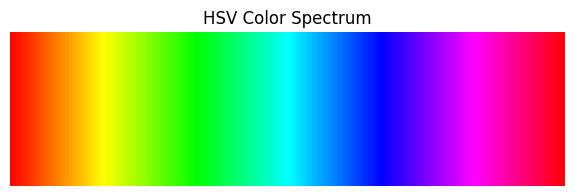

In [3]:
hue_spectrum = np.linspace(0, 179, 180).astype(np.uint8)

hue_row = np.array([hue_spectrum] * 50)
saturation_image = np.ones_like(hue_row, dtype=np.uint8) * 255
value_image = np.ones_like(hue_row, dtype=np.uint8) * 255

hsv_image = cv2.merge([hue_row, saturation_image, value_image])
rgb_image = cv2.cvtColor(hsv_image, cv2.COLOR_HSV2BGR)

plt.figure(figsize=(12, 2))

plt.imshow(cv2.cvtColor(rgb_image, cv2.COLOR_BGR2RGB))
plt.title('HSV Color Spectrum')
plt.xlabel('Hue')
plt.ylabel('Saturation')
plt.axis('off')

plt.show()

In [4]:
uploaded = files.upload()
uploaded_names = list(uploaded.keys())

required_names = [
    'felfel-dolme.jpg',
    'green-sccreen.png',
    'color.png',
    'PopEffects.jpeg'
]

missing_names = [
    name for name in required_names if name not in uploaded_names
]

if missing_names:
    print("Missing Files:")
    for name in missing_names:
        print(name)

image_paths = {
    name: '/content/' + name
    for name in required_names
}

print(image_paths)

Saving color.png to color.png
Saving felfel-dolme.jpg to felfel-dolme.jpg
Saving green-sccreen.png to green-sccreen.png
Saving PopEffects.jpeg to PopEffects.jpeg
{'felfel-dolme.jpg': '/content/felfel-dolme.jpg', 'green-sccreen.png': '/content/green-sccreen.png', 'color.png': '/content/color.png', 'PopEffects.jpeg': '/content/PopEffects.jpeg'}


In [5]:
def plot_hsv_histogram(image_path, title):
    image = cv2.imread(image_path)
    image_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    hist_hue = cv2.calcHist([image_hsv], [0], None, [180], [0, 180])

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title('Original Image')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(1, 3, 2)
    plt.plot(hue_spectrum, hist_hue, color='r')
    plt.xlim([0, 180])
    plt.title('HSV Histogram')
    plt.xlabel('Hue')
    plt.ylabel('Frequency')

    plt.subplot(1, 3, 3)
    plt.imshow(cv2.cvtColor(rgb_image, cv2.COLOR_BGR2RGB))
    plt.title('HSV Color Spectrum')
    plt.xlabel('Hue')
    plt.ylabel('Saturation')
    plt.xticks([])
    plt.yticks([])

    plt.tight_layout()
    plt.show()

    dominant_hue = np.argmax(hist_hue)
    print(f"{title} Dominant Hue: {dominant_hue}")

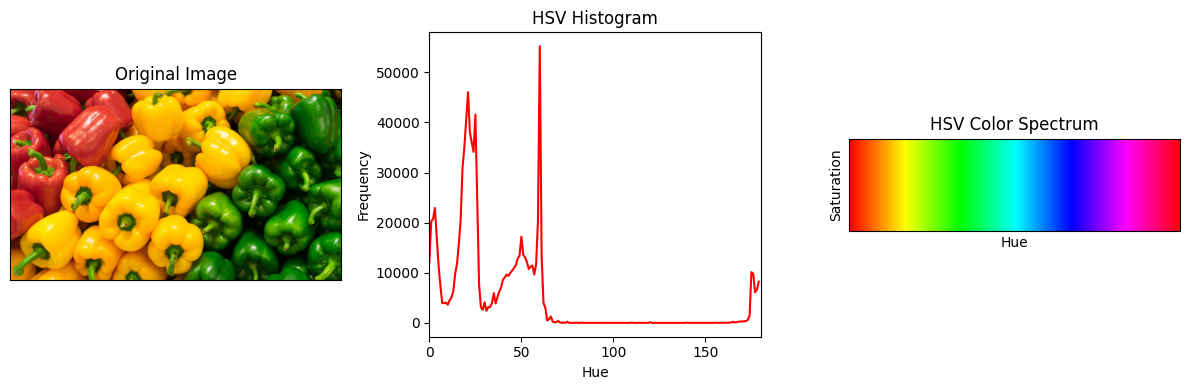

Felfel Dolme Dominant Hue: 60


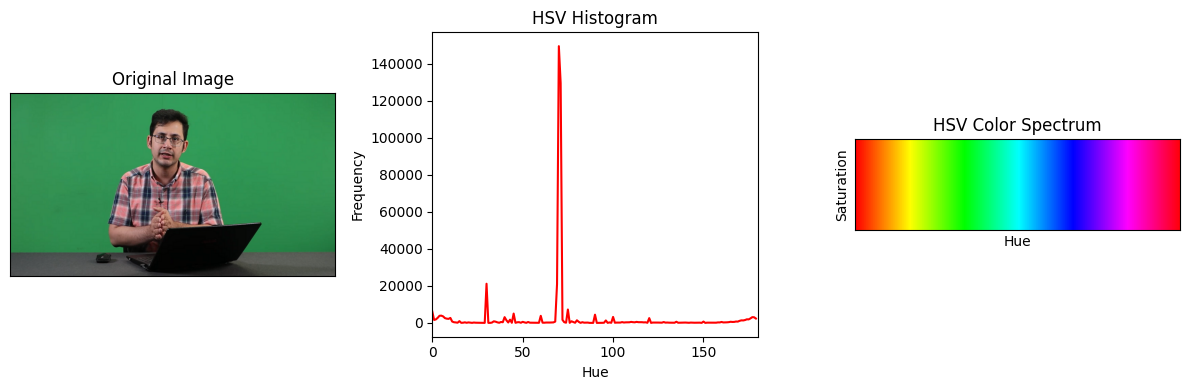

Green Screen Dominant Hue: 70


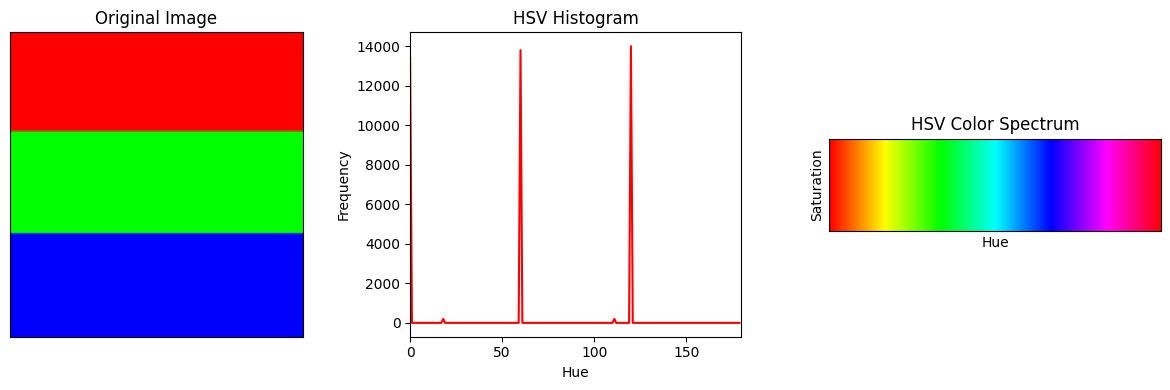

Color Dominant Hue: 120


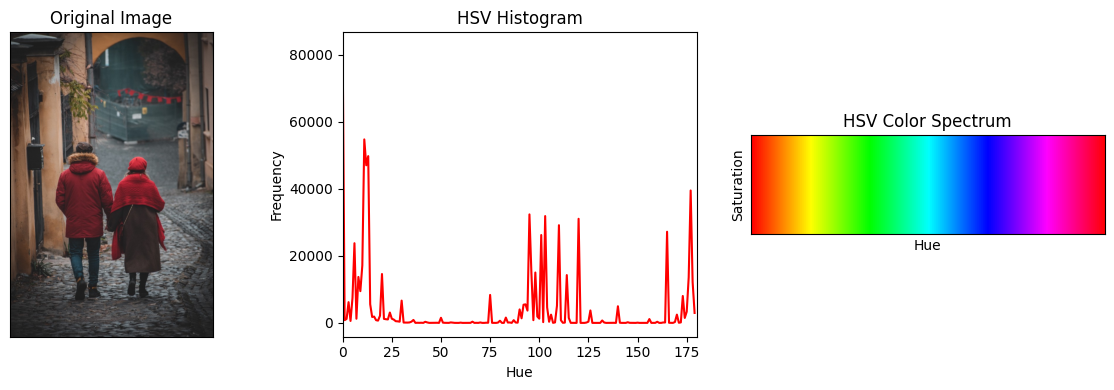

Pop Effects Dominant Hue: 0


In [6]:
plot_hsv_histogram(image_paths['felfel-dolme.jpg'], 'Felfel Dolme')
plot_hsv_histogram(image_paths['green-sccreen.png'], 'Green Screen')
plot_hsv_histogram(image_paths['color.png'], 'Color')
plot_hsv_histogram(image_paths['PopEffects.jpeg'], 'Pop Effects')